## Single Agent

In [1]:
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[{"role": "user", "content": "Say hello!"}]
)
print(response.choices[0].message.content)

Hello! How can I assist you today?


In [2]:
import os, json

for folder in ["data", "tasks", "agents", "results"]:
    os.makedirs(folder, exist_ok=True)

open("data/sales.csv", "w").write("""region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan,9000
East,Feb,15000
West,Feb,17000
North,Feb,11000
""")

open("data/emails.txt", "w").write("""From: Priya
Subject: Meeting change
Can we move Thursday's meeting to Friday at 2 PM?

From: John
Subject: Budget
The marketing budget for Q3 is $40,000, up from $32,000 in Q2.
""")

open("data/employees.csv", "w").write("""name,department,salary
Asha,Engineering,95000
Ben,Marketing,70000
Carlos,Engineering,105000
Dina,Sales,65000
""")

tasks = [
    {"id": 1, "task": "Which region had the highest total revenue in sales.csv?", "answer": "West"},
    {"id": 2, "task": "What is the total revenue for East across all months?", "answer": "27000"},
    {"id": 3, "task": "What day and time did Priya ask to move the meeting to?", "answer": "Friday at 2 PM"},
    {"id": 4, "task": "By what percentage did the marketing budget increase from Q2 to Q3?", "answer": "25%"},
    {"id": 5, "task": "What is the average salary in the Engineering department?", "answer": "100000"}
]
json.dump(tasks, open("tasks/tasks.json", "w"), indent=2)

open(".gitignore", "w").write(".env\n__pycache__/\n.ipynb_checkpoints/\n")

print("Project folder ready!")

Project folder ready!


In [3]:
%%writefile tools.py
import os
import ast
import operator

DATA_DIR = "data"

def read_file(filename: str) -> str:
    """Return the contents of a file in the data folder."""
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        return f"Error: file '{filename}' not found."
    with open(path, "r", encoding="utf-8") as f:
        return f.read()

def list_files() -> str:
    """List all files in the data folder."""
    return ", ".join(os.listdir(DATA_DIR))

# Safe calculator: only allows numbers and + - * / ( )
OPS = {ast.Add: operator.add, ast.Sub: operator.sub,
       ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.USub: operator.neg}

def _eval(node):
    if isinstance(node, ast.Constant):
        return node.value
    if isinstance(node, ast.BinOp):
        return OPS[type(node.op)](_eval(node.left), _eval(node.right))
    if isinstance(node, ast.UnaryOp):
        return OPS[type(node.op)](_eval(node.operand))
    raise ValueError("Unsupported expression")

def calculator(expression: str) -> str:
    """Calculate a math expression like '(40000-32000)/32000*100'."""
    try:
        return str(_eval(ast.parse(expression, mode="eval").body))
    except Exception as e:
        return f"Error: {e}"

Overwriting tools.py


In [4]:
from tools import read_file, list_files, calculator

print(list_files())
print(read_file("sales.csv"))
print(calculator("(40000-32000)/32000*100"))
print(read_file("missing.csv"))

emails.txt, employees.csv, sales.csv
region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan,9000
East,Feb,15000
West,Feb,17000
North,Feb,11000

25.0
Error: file 'missing.csv' not found.


In [5]:
"""Step 1: Create the single agent file"""

'Step 1: Create the single agent file'

In [6]:
%%writefile agents/single_agent.py
import json
from dotenv import load_dotenv
from openai import OpenAI
from tools import read_file, list_files, calculator

load_dotenv()
client = OpenAI()
MODEL = "gpt-4o-mini"

# 1. Describe the tools so GPT knows what it can use
TOOLS = [
    {"type": "function", "function": {
        "name": "list_files",
        "description": "List all files in the data folder.",
        "parameters": {"type": "object", "properties": {}}}},
    {"type": "function", "function": {
        "name": "read_file",
        "description": "Read the full contents of a file in the data folder.",
        "parameters": {"type": "object",
                       "properties": {"filename": {"type": "string", "description": "File name, like sales.csv"}},
                       "required": ["filename"]}}},
    {"type": "function", "function": {
        "name": "calculator",
        "description": "Calculate a math expression using + - * / and parentheses, like (40000-32000)/32000*100",
        "parameters": {"type": "object",
                       "properties": {"expression": {"type": "string"}},
                       "required": ["expression"]}}},
]

# 2. Connect each tool name to the real Python function
TOOL_FUNCTIONS = {"list_files": list_files, "read_file": read_file, "calculator": calculator}

# 3. Instructions for the agent
SYSTEM = ("You are a careful office assistant. Use the tools to read files and do math. "
          "Before saying information is missing, check every file. "
          "Always use the calculator for math. Give a short final answer.")
# 4. The agent loop
def run_single_agent(task, max_steps=8, verbose=True):
    messages = [{"role": "system", "content": SYSTEM},
                {"role": "user", "content": task}]
    total_tokens = 0

    for step in range(max_steps):
        response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS)
        total_tokens += response.usage.total_tokens
        msg = response.choices[0].message

        # No tool needed → this is the final answer
        if not msg.tool_calls:
            return {"answer": msg.content, "steps": step + 1, "tokens": total_tokens}

        # GPT wants tools → run them and send results back
        messages.append(msg)
        for call in msg.tool_calls:
            name = call.function.name
            args = json.loads(call.function.arguments or "{}")
            result = TOOL_FUNCTIONS[name](**args)
            if verbose:
                print(f"  🔧 {name}({args}) → {result[:60]}")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

    return {"answer": "Stopped: too many steps", "steps": max_steps, "tokens": total_tokens}

Overwriting agents/single_agent.py


In [7]:
from agents.single_agent import run_single_agent

result = run_single_agent("Which region had the highest total revenue in sales.csv?")
print(result)

  🔧 list_files({}) → emails.txt, employees.csv, sales.csv
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
  🔧 calculator({'expression': '12000 + 15000'}) → 27000
  🔧 calculator({'expression': '18000 + 17000'}) → 35000
  🔧 calculator({'expression': '9000 + 11000'}) → 20000
{'answer': 'The region with the highest total revenue is the West, with a total revenue of 35,000.', 'steps': 6, 'tokens': 1658}


In [8]:
result = run_single_agent("What is the capital of France?")
print(result)

{'answer': 'The capital of France is Paris.', 'steps': 1, 'tokens': 166}


In [9]:
result = run_single_agent("What was the revenue for the East region in March?")
print(result)


  🔧 list_files({}) → emails.txt, employees.csv, sales.csv
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
{'answer': 'The revenue for the East region in March is missing in the available data.', 'steps': 4, 'tokens': 995}


In [10]:
import json

tasks = json.load(open("tasks/tasks.json"))

def is_correct(agent_answer, correct_answer):
    clean = lambda s: str(s).lower().replace(",", "").replace("$", "")
    return clean(correct_answer) in clean(agent_answer)

score = 0
for t in tasks:
    print(f"\n📝 Task {t['id']}: {t['task']}")
    result = run_single_agent(t["task"], verbose=False)
    correct = is_correct(result["answer"], t["answer"])
    score += correct
    print(f"   Agent said: {result['answer']}")
    print(f"   Correct answer: {t['answer']}  →  {'✅' if correct else '❌'}")
    print(f"   Steps: {result['steps']}, Tokens: {result['tokens']}")

print(f"\n🏆 Final score: {score} / {len(tasks)}")


📝 Task 1: Which region had the highest total revenue in sales.csv?
   Agent said: The region with the highest total revenue is the West, with a total of $35,000.
   Correct answer: West  →  ✅
   Steps: 4, Tokens: 1082

📝 Task 2: What is the total revenue for East across all months?
   Agent said: The total revenue for East across all months is $27,000.
   Correct answer: 27000  →  ✅
   Steps: 4, Tokens: 955

📝 Task 3: What day and time did Priya ask to move the meeting to?
   Agent said: Priya asked to move the meeting to Friday at 2 PM.
   Correct answer: Friday at 2 PM  →  ✅
   Steps: 3, Tokens: 663

📝 Task 4: By what percentage did the marketing budget increase from Q2 to Q3?
   Agent said: The marketing budget increased by 25% from Q2 to Q3.
   Correct answer: 25%  →  ✅
   Steps: 4, Tokens: 1321

📝 Task 5: What is the average salary in the Engineering department?
   Agent said: The average salary in the Engineering department is $100,000.
   Correct answer: 100000  →  ✅
   Steps: 

In [11]:
for t in tasks:
    result = run_single_agent(t["task"], verbose=True)
    if not is_correct(result["answer"], t["answer"]):
        print(f"\n❌ Task {t['id']}: {t['task']}")
        print(f"   Agent said:     {result['answer']}")
        print(f"   Correct answer: {t['answer']}")

  🔧 list_files({}) → emails.txt, employees.csv, sales.csv
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
  🔧 calculator({'expression': '12000 + 15000'}) → 27000
  🔧 calculator({'expression': '18000 + 17000'}) → 35000
  🔧 calculator({'expression': '9000 + 11000'}) → 20000
  🔧 list_files({}) → emails.txt, employees.csv, sales.csv
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
  🔧 calculator({'expression': '12000 + 15000'}) → 27000
  🔧 list_files({}) → emails.txt, employees.csv, sales.csv
  🔧 read_file({'filename': 'emails.txt'}) → From: Priya
Subject: Meeting change
Can we move Thursday's m
  🔧 list_files({}) → emails.txt, employees.csv, sales.csv
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
  🔧 read_file({'filename

In [12]:
# 1. TOOLS is a menu that describes each tool so GPT understand what tool use
# 2. TOOL_FUNCTIONS is like a phone book that GPT finds real tool to run
# 3. max_steps is a safety brake. it stops the agent after 8 rounds so reduce cost
# 4. messages is like a notebook we add the tool and GPT read it in next rounnd
# 5. The agent stops when GPT doesn't ask for any tool

In [13]:
print(run_single_agent("By what percentage did the marketing budget increase from Q2 to Q3?", verbose=True))

  🔧 list_files({}) → emails.txt, employees.csv, sales.csv
  🔧 read_file({'filename': 'employees.csv'}) → name,department,salary
Asha,Engineering,95000
Ben,Marketing,
  🔧 read_file({'filename': 'sales.csv'}) → region,month,revenue
East,Jan,12000
West,Jan,18000
North,Jan
  🔧 read_file({'filename': 'emails.txt'}) → From: Priya
Subject: Meeting change
Can we move Thursday's m
  🔧 calculator({'expression': '(40000-32000)/32000*100'}) → 25.0
{'answer': 'The marketing budget increased by 25% from Q2 to Q3.', 'steps': 4, 'tokens': 1321}


## Multi Agent

In [14]:
SYSTEM = ("You are a helpful office assistant. Use the tools to read files and do math. "
          "Always use the calculator for math. Give a short final answer.")

In [15]:
%%writefile agents/multi_agent.py
import json
from agents.single_agent import client, MODEL, TOOLS, TOOL_FUNCTIONS
from tools import list_files

# 🗺️ Planner: makes the plan, does not solve
PLANNER_PROMPT = ("You are a planner. Do NOT solve the task and do NOT give the answer. "
                  "Look at the task and the list of available files. "
                  "Write a short numbered plan (3 to 5 steps) saying which files to read and what to calculate. "
                  "If you are not sure which file has the information, plan to read every file.")

# 👷 Worker: follows the plan using tools
WORKER_PROMPT = ("You are a careful office worker. Follow the plan step by step using the tools. "
                 "Always use the calculator for math. Give a short final answer.")

# 🔍 Checker: reviews the worker's work, cannot open files
CHECKER_PROMPT = ("You are a reviewer. You cannot open files, but you can see what the worker's tools returned. "
                  "Use those tool results to check if the worker's answer is correct and complete. "
                  "If the worker said information is missing but did not read all the files, that is a mistake. "
                  "If the tool results support the answer, reply with exactly: OK. "
                  "Otherwise, explain the problem in one or two sentences.")


def call_model(system, user, use_tools=False, max_steps=8, verbose=True):
    """Call GPT with a job description. If use_tools=True, it can use tools in a loop."""
    messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    tokens, trace = 0, []
    for step in range(max_steps):
        if use_tools:
            response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS)
        else:
            response = client.chat.completions.create(model=MODEL, messages=messages)
        tokens += response.usage.total_tokens
        msg = response.choices[0].message
        if not msg.tool_calls:
            return msg.content, tokens, trace, step + 1
        messages.append(msg)
        for call in msg.tool_calls:
            name = call.function.name
            args = json.loads(call.function.arguments or "{}")
            result = TOOL_FUNCTIONS[name](**args)
            trace.append(f"{name}({args}) returned:\n{result}")
            if verbose:
                print(f"     🔧 {name}({args})")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    return "Stopped: too many steps", tokens, trace, max_steps


def run_multi_agent(task, max_retries=3, verbose=True):
    total_tokens, total_steps = 0, 0

    # 1. Planner makes the plan
    plan, t, _, s = call_model(PLANNER_PROMPT, f"Task: {task}\nAvailable files: {list_files()}")
    total_tokens += t; total_steps += s
    if verbose:
        print(f"  🗺️ Plan:\n{plan}\n")

    feedback = ""
    for attempt in range(max_retries + 1):
        # 2. Worker follows the plan with tools
        answer, t, trace, s = call_model(WORKER_PROMPT, f"Task: {task}\nPlan:\n{plan}\n{feedback}",
                                         use_tools=True, verbose=verbose)
        total_tokens += t; total_steps += s
        if verbose:
            print(f"  👷 Worker answer: {answer}")

        # 3. Checker reviews the answer
        check_input = (f"Task: {task}\nAvailable files: {list_files()}\n"
                       f"Tools the worker used:\n" + "\n\n".join(trace) +
                       f"\n\nWorker's answer: {answer}")
        verdict, t, _, s = call_model(CHECKER_PROMPT, check_input)
        total_tokens += t; total_steps += s
        if verbose:
            print(f"  🔍 Checker: {verdict}\n")

        clean_verdict = verdict.strip().rstrip(".").upper()
        if clean_verdict.startswith("OK") or clean_verdict.endswith("OK"):
            break
        feedback = f"A reviewer found a problem with your last answer: {verdict}\nPlease fix it."

    return {"answer": answer, "steps": total_steps, "tokens": total_tokens}

Overwriting agents/multi_agent.py


In [16]:
from agents.multi_agent import run_multi_agent

print(run_multi_agent("By what percentage did the marketing budget increase from Q2 to Q3?"))

  🗺️ Plan:
1. Read the `emails.txt` file to check for any communications regarding budget changes or approvals related to the marketing budget for Q2 and Q3.
2. Review the `sales.csv` file to find any relevant financial data that might include information about the marketing budget for Q2 and Q3.
3. If necessary, examine the `employees.csv` file to see if there are any related notes or comments about budget allocations or changes in the marketing department that could help clarify the budget changes.
4. Calculate the percentage increase in the marketing budget from Q2 to Q3 using the information gathered.

     🔧 read_file({'filename': 'emails.txt'})
     🔧 read_file({'filename': 'sales.csv'})
     🔧 read_file({'filename': 'employees.csv'})
     🔧 calculator({'expression': '(40000-32000)/32000*100'})
  👷 Worker answer: The marketing budget increased by 25% from Q2 to Q3.
  🔍 Checker: OK

{'answer': 'The marketing budget increased by 25% from Q2 to Q3.', 'steps': 5, 'tokens': 1978}


In [17]:
import json
from agents.single_agent import run_single_agent
from agents.multi_agent import run_multi_agent

tasks = json.load(open("tasks/tasks.json"))

def is_correct(agent_answer, correct_answer):
    clean = lambda s: str(s).lower().replace(",", "").replace("$", "")
    return clean(correct_answer) in clean(agent_answer)

for name, agent in [("Single agent", run_single_agent), ("Multi-agent team", run_multi_agent)]:
    score, tokens = 0, 0
    print(f"\n===== {name} =====")
    for t in tasks:
        result = agent(t["task"], verbose=False)
        ok = is_correct(result["answer"], t["answer"])
        score += ok
        tokens += result["tokens"]
        print(f"Task {t['id']}: {'✅' if ok else '❌'}  ({result['tokens']} tokens)")
    print(f"🏆 Score: {score}/{len(tasks)}   Total tokens: {tokens}")


===== Single agent =====
Task 1: ✅  (1079 tokens)
Task 2: ✅  (1572 tokens)
Task 3: ✅  (663 tokens)
Task 4: ✅  (1321 tokens)
Task 5: ✅  (938 tokens)
🏆 Score: 5/5   Total tokens: 5573

===== Multi-agent team =====
Task 1: ✅  (2124 tokens)
Task 2: ✅  (1905 tokens)
Task 3: ✅  (2779 tokens)
Task 4: ✅  (2155 tokens)
Task 5: ✅  (1571 tokens)
🏆 Score: 5/5   Total tokens: 10534


In [18]:
SYSTEM = ("You are a helpful office assistant. Use the tools to read files and do math. "
          "Always use the calculator for math. Give a short final answer.")

In [19]:
from agents.multi_agent import run_multi_agent

print(run_multi_agent("What is the total revenue for East across all months?"))
print(run_multi_agent("What is the average salary in the Engineering department?"))
print(run_multi_agent("By what percentage did the marketing budget increase from Q2 to Q3?"))

  🗺️ Plan:
1. Read the `sales.csv` file to find the revenue data specific to the East region and note the revenue for each month.
2. Summarize the revenue data obtained from the `sales.csv` file to calculate the total revenue for the East region across all months.
3. If necessary, review the `employees.csv` file to understand any possible relationships between employees and sales that might affect revenue (though this is likely not directly related to the task).
4. Check the `emails.txt` file for any relevant communication regarding sales or revenue that might provide additional insights or context.
5. Compile the total revenue for the East region based on the calculations done in step 2 and any relevant information from steps 3 and 4.

     🔧 list_files({})
     🔧 read_file({'filename': 'sales.csv'})
     🔧 calculator({'expression': '12000 + 15000'})
     🔧 read_file({'filename': 'employees.csv'})
     🔧 read_file({'filename': 'emails.txt'})
  👷 Worker answer: 1. The revenue for the E

In [20]:
import json

tasks = json.load(open("tasks/tasks.json"))

# Add difficulty labels to the first 5 tasks
labels = {1: "medium", 2: "medium", 3: "easy", 4: "hard", 5: "medium"}
for t in tasks:
    t["difficulty"] = labels[t["id"]]

# Add 5 new easy tasks
new_tasks = [
    {"id": 6,  "task": "What was West's revenue in January?",       "answer": "18000", "difficulty": "easy"},
    {"id": 7,  "task": "Which department does Dina work in?",       "answer": "Sales", "difficulty": "easy"},
    {"id": 8,  "task": "What is Ben's salary?",                     "answer": "70000", "difficulty": "easy"},
    {"id": 9,  "task": "What was the marketing budget in Q3?",      "answer": "40000", "difficulty": "easy"},
    {"id": 10, "task": "What was North's revenue in February?",     "answer": "11000", "difficulty": "easy"},
]
tasks.extend(new_tasks)

json.dump(tasks, open("tasks/tasks.json", "w"), indent=2)
print(f"✅ Saved {len(tasks)} tasks")

✅ Saved 10 tasks


In [21]:
open("data/calendar.csv", "w").write("""date,day,event,time,room
2026-11-02,Monday,Team standup,09:00,Room A
2026-11-03,Tuesday,Client call,14:00,Room B
2026-11-05,Thursday,Budget review,11:00,Room A
2026-11-06,Friday,Product demo,15:00,Room C
""")

open("data/inventory.csv", "w").write("""item,category,quantity,unit_price
Laptop,Electronics,12,900
Monitor,Electronics,20,200
Desk,Furniture,8,350
Chair,Furniture,25,120
Printer,Electronics,3,250
""")

print("✅ 2 new files added")

✅ 2 new files added


In [22]:
import json

tasks = json.load(open("tasks/tasks.json"))

tasks.extend([
    {"id": 11, "task": "Which room is the Product demo in?",             "answer": "Room C",   "difficulty": "easy"},
    {"id": 12, "task": "How many chairs are in the inventory?",          "answer": "25",       "difficulty": "easy"},
    {"id": 13, "task": "What is the unit price of a Monitor?",           "answer": "200",      "difficulty": "easy"},
    {"id": 14, "task": "On which day of the week is the Budget review?", "answer": "Thursday", "difficulty": "easy"},
])

json.dump(tasks, open("tasks/tasks.json", "w"), indent=2)
print(f"✅ Saved {len(tasks)} tasks")

✅ Saved 14 tasks


In [23]:
import json

tasks = json.load(open("tasks/tasks.json"))

tasks.extend([
    {"id": 15, "task": "How many Electronics items are in the inventory in total?",       "answer": "35",     "difficulty": "medium"},
    {"id": 16, "task": "What is the total value of all Laptops (quantity × unit price)?", "answer": "10800",  "difficulty": "medium"},
    {"id": 17, "task": "What is the total salary of all employees?",                      "answer": "335000", "difficulty": "medium"},
    {"id": 18, "task": "What was the total revenue for all regions in January?",          "answer": "39000",  "difficulty": "medium"},
    {"id": 19, "task": "What is the average unit price of Furniture items?",              "answer": "235",    "difficulty": "medium"},
    {"id": 20, "task": "What is the total salary of Carlos's department minus the total salary of Dina's department?",
                                                                                          "answer": "135000", "difficulty": "medium"},
    {"id": 21, "task": "What is the Monitor quantity minus the average quantity of Laptops and Printers?",
                                                                                          "answer": "12.5",   "difficulty": "medium"},
])

json.dump(tasks, open("tasks/tasks.json", "w"), indent=2)
print(f"✅ Saved {len(tasks)} tasks")

✅ Saved 21 tasks


In [24]:
import json

tasks = json.load(open("tasks/tasks.json"))

tasks.extend([
    {"id": 22, "task": "How much higher is Ben's salary than the Q3 marketing budget?",
     "answer": "30000", "difficulty": "hard"},
    {"id": 23, "task": "If the marketing budget grows by the same dollar amount from Q3 to Q4 as it did from Q2 to Q3, what will the Q4 budget be?",
     "answer": "48000", "difficulty": "hard"},
    {"id": 24, "task": "What is the total value of all items in the inventory (quantity × unit price)?",
     "answer": "21350", "difficulty": "hard"},
    {"id": 25, "task": "Priya asked to move a meeting to a new day. Which event in the calendar is already scheduled on that day?",
     "answer": "Product demo", "difficulty": "hard"},
    {"id": 26, "task": "What is the total revenue of the region with the highest January revenue, minus the total value of all Electronics in the inventory?",
     "answer": "19450", "difficulty": "hard"},
    {"id": 27, "task": "Engineering wants to buy one Laptop and one Monitor for each Engineering employee. Using the inventory unit prices, what is the total cost?",
     "answer": "2200", "difficulty": "hard"},
    {"id": 28, "task": "How much higher is the total salary of all employees than the total revenue of all regions across all months?",
     "answer": "253000", "difficulty": "hard"},
    {"id": 29, "task": "What percentage of total revenue (all regions, all months) came from the East region? Round to one decimal place.",
     "answer": "32.9", "difficulty": "hard"},
    {"id": 30, "task": "If the Q3 marketing budget is used to buy all the Chairs and Desks in the inventory, how much money is left over?",
     "answer": "34200", "difficulty": "hard"},
])

json.dump(tasks, open("tasks/tasks.json", "w"), indent=2)
print(f"✅ Saved {len(tasks)} tasks")

✅ Saved 30 tasks


In [25]:
import json, csv, time, io, os
from contextlib import redirect_stdout
from agents.single_agent import run_single_agent
from agents.multi_agent import run_multi_agent

tasks = json.load(open("tasks/tasks.json"))

def is_correct(agent_answer, correct_answer):
    clean = lambda s: str(s).lower().replace(",", "").replace("$", "")
    return clean(correct_answer) in clean(agent_answer)

RESULTS = "results/results.csv"
LOGS = "results/logs"
os.makedirs(LOGS, exist_ok=True)
fields = ["system", "task_id", "difficulty", "run", "correct", "steps", "tokens", "seconds", "answer"]

# Start a fresh results file with column names
with open(RESULTS, "w", newline="", encoding="utf-8") as f:
    csv.DictWriter(f, fieldnames=fields).writeheader()

systems = [("single", run_single_agent), ("multi", run_multi_agent)]
total = len(systems) * len(tasks) * 3
count = 0

for run in range(1, 4):                     # 3 runs
    for t in tasks:                         # 30 tasks
        for name, agent in systems:         # 2 systems
            count += 1
            log = io.StringIO()
            start = time.time()
            try:
                with redirect_stdout(log):  # save the 🔧 details into a log
                    result = agent(t["task"], verbose=True)
            except Exception as e:
                result = {"answer": f"ERROR: {e}", "steps": 0, "tokens": 0}
            seconds = round(time.time() - start, 1)
            ok = is_correct(result["answer"], t["answer"])

            row = {"system": name, "task_id": t["id"], "difficulty": t["difficulty"], "run": run,
                   "correct": ok, "steps": result["steps"], "tokens": result["tokens"],
                   "seconds": seconds, "answer": result["answer"]}

            # Save this result right away
            with open(RESULTS, "a", newline="", encoding="utf-8") as f:
                csv.DictWriter(f, fieldnames=fields).writerow(row)
            with open(f"{LOGS}/{name}_task{t['id']}_run{run}.txt", "w", encoding="utf-8") as f:
                f.write(log.getvalue())

            print(f"[{count}/{total}] {name:6} | Task {t['id']:2} ({t['difficulty']:6}) | Run {run}: "
                  f"{'✅' if ok else '❌'}  {result['tokens']} tokens, {seconds}s")

print("\n🎉 Experiment finished! Results saved to results/results.csv")

[1/180] single | Task  1 (medium) | Run 1: ✅  1688 tokens, 5.6s
[2/180] multi  | Task  1 (medium) | Run 1: ✅  1890 tokens, 6.3s
[3/180] single | Task  2 (medium) | Run 1: ✅  1395 tokens, 3.8s
[4/180] multi  | Task  2 (medium) | Run 1: ✅  2417 tokens, 4.9s
[5/180] single | Task  3 (easy  ) | Run 1: ✅  677 tokens, 2.5s
[6/180] multi  | Task  3 (easy  ) | Run 1: ✅  1835 tokens, 4.9s
[7/180] single | Task  4 (hard  ) | Run 1: ✅  3123 tokens, 5.7s
[8/180] multi  | Task  4 (hard  ) | Run 1: ✅  5354 tokens, 8.5s
[9/180] single | Task  5 (medium) | Run 1: ✅  956 tokens, 3.2s
[10/180] multi  | Task  5 (medium) | Run 1: ✅  1911 tokens, 4.9s
[11/180] single | Task  6 (easy  ) | Run 1: ✅  649 tokens, 2.0s
[12/180] multi  | Task  6 (easy  ) | Run 1: ✅  2287 tokens, 6.4s
[13/180] single | Task  7 (easy  ) | Run 1: ✅  631 tokens, 2.0s
[14/180] multi  | Task  7 (easy  ) | Run 1: ✅  1586 tokens, 4.6s
[15/180] single | Task  8 (easy  ) | Run 1: ✅  629 tokens, 2.0s
[16/180] multi  | Task  8 (easy  ) | Ru

In [26]:
print("\n Experiment finished! Results saved to results/results.csv")


 Experiment finished! Results saved to results/results.csv


In [27]:
import pandas as pd

df = pd.read_csv("results/results.csv")
wrong = df[df["correct"] == False]
for _, r in wrong.iterrows():
    print(f"{r['system']:6} | Task {r['task_id']} | Run {r['run']}: {r['answer'][:150]}\n")

single | Task 19 | Run 1: The average unit price of Furniture items is approximately $175.76.

single | Task 22 | Run 1: Ben's salary is $70,000. However, I could not find the Q3 marketing budget in the available files. So I can't calculate the difference.

single | Task 25 | Run 1: Please provide the new day to see if there is an event scheduled for that date.

single | Task 26 | Run 1: The total revenue of the region with the highest January revenue, minus the total value of all Electronics in the inventory, is 2450.

multi  | Task 26 | Run 1: The total revenue of the region with the highest January revenue, minus the total value of all Electronics in inventory, is **2450**.

single | Task 30 | Run 1: After using the Q3 marketing budget to buy all the chairs and desks in the inventory, there is $35,200 left over.

single | Task 4 | Run 2: It appears that the relevant data for the marketing budget is not available in the files. The files examined do not contain any information regardi

In [28]:
df = pd.read_csv("results/results.csv")
print(df.groupby(["difficulty", "system"]).agg(
    accuracy=("correct", "mean"), avg_tokens=("tokens", "mean"), avg_seconds=("seconds", "mean")).round(2))

                   accuracy  avg_tokens  avg_seconds
difficulty system                                   
easy       multi       1.00     2571.57         6.19
           single      1.00      845.87         2.47
hard       multi       0.83     5041.50         9.62
           single      0.53     1726.83         4.31
medium     multi       1.00     2284.57         5.69
           single      0.90     1125.63         3.38


In [29]:
import pandas as pd

df = pd.read_csv("results/results.csv")
tasks_df = pd.DataFrame(tasks)[["id", "answer"]].rename(columns={"id": "task_id", "answer": "correct_answer"})
wrong = df[df["correct"] == False].merge(tasks_df, on="task_id")

for task_id, group in wrong.groupby("task_id"):
    print(f"========== Task {task_id} (correct answer: {group['correct_answer'].iloc[0]}) ==========")
    for _, r in group.iterrows():
        print(f"  {r['system']:6} | Run {r['run']}: {r['answer'][:200]}")
    print()

========== Task 4 (correct answer: 25%) ==========
  single | Run 2: It appears that the relevant data for the marketing budget is not available in the files. The files examined do not contain any information regarding the marketing budget for Q2 or Q3.
  single | Run 3: Stopped: too many steps

========== Task 19 (correct answer: 235) ==========
  single | Run 1: The average unit price of Furniture items is approximately $175.76.
  single | Run 2: The average unit price of Furniture items is approximately $175.76.
  single | Run 3: The average unit price of Furniture items is approximately $175.76.

========== Task 22 (correct answer: 30000) ==========
  single | Run 1: Ben's salary is $70,000. However, I could not find the Q3 marketing budget in the available files. So I can't calculate the difference.
  single | Run 3: It seems I don't have the Q3 marketing budget data available. The files reviewed only contain Ben's salary information. Ben's salary is $70,000. Please provide the Q3

In [30]:
clean_df = df[~df["task_id"].isin([19, 26])]
print(clean_df.groupby(["difficulty", "system"])["correct"].mean().round(2))

difficulty  system
easy        multi     1.00
            single    1.00
hard        multi     0.93
            single    0.59
medium      multi     1.00
            single    1.00
Name: correct, dtype: float64


In [31]:
%%writefile agents/single_agent_rule.py
import json
from agents.single_agent import client, MODEL, TOOLS, TOOL_FUNCTIONS

# Same as the original single agent, plus the Planner's rule (last sentence)
SYSTEM = ("You are a helpful office assistant. Use the tools to read files and do math. "
          "Always use the calculator for math. Give a short final answer. "
          "If you are not sure which file has the information, read every file.")

def run_single_agent_rule(task, max_steps=8, verbose=True):
    messages = [{"role": "system", "content": SYSTEM},
                {"role": "user", "content": task}]
    total_tokens = 0
    for step in range(max_steps):
        response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS)
        total_tokens += response.usage.total_tokens
        msg = response.choices[0].message
        if not msg.tool_calls:
            return {"answer": msg.content, "steps": step + 1, "tokens": total_tokens}
        messages.append(msg)
        for call in msg.tool_calls:
            name = call.function.name
            args = json.loads(call.function.arguments or "{}")
            result = TOOL_FUNCTIONS[name](**args)
            if verbose:
                print(f"  🔧 {name}({args}) → {result[:60]}")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    return {"answer": "Stopped: too many steps", "steps": max_steps, "tokens": total_tokens}

Writing agents/single_agent_rule.py


In [32]:
import json, csv, time, io, os
from contextlib import redirect_stdout
from agents.single_agent_rule import run_single_agent_rule

tasks = json.load(open("tasks/tasks.json"))

def is_correct(agent_answer, correct_answer):
    clean = lambda s: str(s).lower().replace(",", "").replace("$", "")
    return clean(correct_answer) in clean(agent_answer)

RESULTS, LOGS = "results/results.csv", "results/logs"
fields = ["system", "task_id", "difficulty", "run", "correct", "steps", "tokens", "seconds", "answer"]
count = 0

for run in range(1, 4):
    for t in tasks:
        count += 1
        log = io.StringIO()
        start = time.time()
        try:
            with redirect_stdout(log):
                result = run_single_agent_rule(t["task"], verbose=True)
        except Exception as e:
            result = {"answer": f"ERROR: {e}", "steps": 0, "tokens": 0}
        seconds = round(time.time() - start, 1)
        ok = is_correct(result["answer"], t["answer"])

        row = {"system": "single_rule", "task_id": t["id"], "difficulty": t["difficulty"], "run": run,
               "correct": ok, "steps": result["steps"], "tokens": result["tokens"],
               "seconds": seconds, "answer": result["answer"]}
        with open(RESULTS, "a", newline="", encoding="utf-8") as f:   # "a" = add, don't erase
            csv.DictWriter(f, fieldnames=fields).writerow(row)
        with open(f"{LOGS}/single_rule_task{t['id']}_run{run}.txt", "w", encoding="utf-8") as f:
            f.write(log.getvalue())

        print(f"[{count}/90] single_rule | Task {t['id']:2} ({t['difficulty']:6}) | Run {run}: "
              f"{'✅' if ok else '❌'}  {result['tokens']} tokens, {seconds}s")

print("\n🎉 Done! Added to results/results.csv")

[1/90] single_rule | Task  1 (medium) | Run 1: ✅  1711 tokens, 4.9s
[2/90] single_rule | Task  2 (medium) | Run 1: ✅  1420 tokens, 4.2s
[3/90] single_rule | Task  3 (easy  ) | Run 1: ✅  846 tokens, 2.2s
[4/90] single_rule | Task  4 (hard  ) | Run 1: ✅  1731 tokens, 3.7s
[5/90] single_rule | Task  5 (medium) | Run 1: ✅  976 tokens, 2.7s
[6/90] single_rule | Task  6 (easy  ) | Run 1: ✅  664 tokens, 1.9s
[7/90] single_rule | Task  7 (easy  ) | Run 1: ✅  770 tokens, 2.7s
[8/90] single_rule | Task  8 (easy  ) | Run 1: ✅  644 tokens, 1.8s
[9/90] single_rule | Task  9 (easy  ) | Run 1: ✅  4352 tokens, 7.2s
[10/90] single_rule | Task 10 (easy  ) | Run 1: ✅  664 tokens, 1.8s
[11/90] single_rule | Task 11 (easy  ) | Run 1: ✅  1054 tokens, 2.9s
[12/90] single_rule | Task 12 (easy  ) | Run 1: ✅  666 tokens, 1.9s
[13/90] single_rule | Task 13 (easy  ) | Run 1: ✅  786 tokens, 2.5s
[14/90] single_rule | Task 14 (easy  ) | Run 1: ✅  833 tokens, 2.4s
[15/90] single_rule | Task 15 (medium) | Run 1: ✅  9

In [33]:
import pandas as pd

df = pd.read_csv("results/results.csv")
clean_df = df[~df["task_id"].isin([19, 26])]
print(clean_df.groupby(["difficulty", "system"]).agg(
    accuracy=("correct", "mean"), avg_tokens=("tokens", "mean")).round(2))

                        accuracy  avg_tokens
difficulty system                           
easy       multi            1.00     2571.57
           single           1.00      845.87
           single_rule      1.00      909.83
hard       multi            0.93     5246.33
           single           0.59     1776.15
           single_rule      0.78     1748.81
medium     multi            1.00     2297.93
           single           1.00     1122.70
           single_rule      1.00     1145.63


In [34]:
   rule_wrong = clean_df[(clean_df["system"] == "single_rule") & (clean_df["correct"] == False)]
   print(rule_wrong[["task_id", "run", "answer"]].to_string())

     task_id  run                                                                                                                                                                                                                         answer
201       22    1  I couldn't find the Q3 marketing budget from the files I accessed. It seems that only Ben's salary is available, which is $70,000. Please provide the Q3 marketing budget for comparison, or verify if it is in another file.
209       30    1                                                                                                                                     After using the Q3 marketing budget to buy all the Chairs and Desks, $76,200 is left over.
234       25    2                                                             To determine which event is already scheduled on the new day, I need to know the specific day Priya wants to move the meeting to. Please provide that information.
239       30    2                   

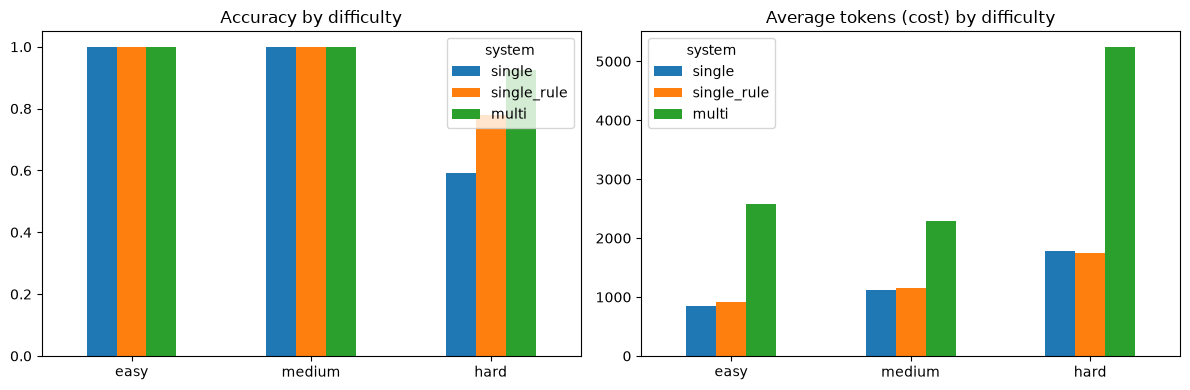

In [35]:
import matplotlib.pyplot as plt

order = ["single", "single_rule", "multi"]
summary = clean_df.groupby(["difficulty", "system"]).agg(
    accuracy=("correct", "mean"), tokens=("tokens", "mean")).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy by difficulty"),
                          (axes[1], "tokens", "Average tokens (cost) by difficulty")]:
    table = summary.pivot(index="difficulty", columns="system", values=metric)
    table = table.loc[["easy", "medium", "hard"], order]
    table.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(title)
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig("results/charts.png", dpi=150)
plt.show()